# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3381 Бескончин Максим Альбертович. Вариант №1.

СПбГЭТУ «ЛЭТИ» · Обработка сигналов · 2026

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

### Линейная стационарная дискретная система

Дискретный сигнал $x[n]$ состоит из отсчётов в моменты $t_n=nT$, где $T=1/f_s$.
В линейной системе умножение воздействия на число умножает реакцию на то же число, а реакция на сумму воздействий равна сумме реакций. В стационарной системе задержка воздействия задерживает реакцию на то же число отсчётов.
Её импульсная характеристика $h[n]$ — реакция на единичный импульс $\delta[n]$ при нулевых начальных условиях. Выход определяется свёрткой:

$$y[n]=(x*h)[n]=\sum_{m=-\infty}^{\infty}x[m]h[n-m].$$

Для причинной системы $h[n]=0$ при $n<0$. Передаточная функция рекурсивного звена второго порядка:

$$H(z)=\frac{Y(z)}{X(z)}=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}},$$
$$y[n]=b_0x[n]+b_1x[n-1]+b_2x[n-2]-a_1y[n-1]-a_2y[n-2].$$

Нули — корни числителя, полюсы — корни знаменателя после приведения к полиномам по $z$.
Система устойчива, если ограниченный вход даёт ограниченный выход. Для причинной системы с рациональной передаточной функцией это выполняется, когда модули всех полюсов меньше 1.

### Частотная характеристика и шкалы

$$H(e^{j\hat\omega})=H(z)\big|_{z=e^{j\hat\omega}},\qquad A(\hat\omega)=|H(e^{j\hat\omega})|,\qquad \varphi(\hat\omega)=\arg H(e^{j\hat\omega}).$$

Здесь $A(\hat\omega)$ — амплитудно-частотная характеристика (АЧХ), $\varphi(\hat\omega)$ — фазочастотная характеристика (ФЧХ).
$\hat\omega=2\pi f/f_s$ — нормированная угловая частота (рад/отсчёт),
$\nu=\hat f=f/f_s=\hat\omega/(2\pi)$ — частота в циклах/отсчёт.
Основная двусторонняя полоса: $-\pi\leq\hat\omega<\pi$ или $-f_s/2\leq f<f_s/2$;
для вещественных сигналов достаточно положительной половины $0\leq\hat\omega\leq\pi$.
При нулевой АЧХ фаза не определена.

### ДПФ, спектр и восстановление

Прямое и обратное ДПФ:

$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad x[n]=\frac1N\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.$$

Амплитудный спектр периодической последовательности — $|X[k]|$, фазовый — $\arg X[k]$.
Коэффициенты ряда Фурье $C[k]=X[k]/N$ используются для восстановления аналогового сигнала.
Если частота косинуса совпадает с узлом сетки ДПФ и $0<f_0<f_s/2$, модули линий при $\pm f_0$ равны $NA/2$, где $A$ — амплитуда косинуса.
Соответствующие коэффициенты $C$ имеют модуль $A/2$.
Фаза коэффициента, равного нулю, не определена.

После перестановки $X_a[k]=X[k\bmod N]$, $-N/2\leq k<N/2$:

$$x_{rec}(t)=\frac1N\sum_{k=-N/2}^{N/2-1}X_a[k]e^{j2\pi kt/(NT)}.$$

Для данной суммы косинусов восстановление точно, если частоты входят в сетку $k/(NT)$ и ниже $f_s/2$.
Равенство Парсеваля:

$$\sum_{n=0}^{N-1}|x[n]|^2=\frac1N\sum_{k=0}^{N-1}|X[k]|^2,\qquad P=\frac1N\sum_n|x[n]|^2=\sum_k|C[k]|^2.$$

Первая сумма — энергия блока из $N$ отсчётов; $P$ — средняя мощность периодического сигнала.

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

### Порядок выполнения

В части 1 требуется вычислить импульсную характеристику системы и её реакцию на прямоугольный импульс двумя способами: свёрткой и по разностному уравнению. Затем найти нули и полюсы, построить их карту, проверить устойчивость и получить АЧХ и ФЧХ в нормированной шкале и в герцах.

В части 2 требуется сформировать сумму двух косинусов, построить её амплитудный и фазовый спектры, выполнить обратное ДПФ и сравнить спектры периодической последовательности и конечного блока. По коэффициентам ДПФ восстановить аналоговый сигнал, сравнить его с исходным и проверить равенство Парсеваля.

## Выполнение работы

### Подготовка и параметры варианта 1

| Часть 1 | Значение | Часть 2 | Значение |
|:--|--:|:--|--:|
| b₀, b₁, b₂ | 0.52; 0.52; 0.52 | N | 64 |
| a₀, a₁, a₂ | 1; −0.8028; 0.646 | fₛ | 4000 Гц |
| N₁ | 21 | T | 0.00025 с |
| N₂ | 31 | A₁, A₂ | 1.01; 2.02 |
| fₛ | 1000 Гц | f₁, f₂ | 500; 750 Гц |

Функция $\mathrm{int}$ обозначает округление до ближайшего целого. Для варианта 1 $\mathrm{int}(N_2/2)=\mathrm{int}(15.5)=16$. Начальные условия нулевые.

Во второй части $f_s=4000$ Гц, поэтому $f_1=4000/8=500$ Гц и $f_2=1.5f_1=750$ Гц.

In [1]:
from pathlib import Path
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline

OUT = Path("figures")
OUT.mkdir(exist_ok=True)
plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "figure.dpi": 120,
        "font.size": 11,
        "axes.grid": True,
        "grid.alpha": 0.22,
    }
)

In [2]:
def finish(fig, name):
    fig.tight_layout(pad=1.5)
    fig.savefig(OUT / (name + ".png"), bbox_inches="tight", dpi=170)
    plt.show()
    plt.close(fig)


def stems(ax, xx, yy, title, xlabel, ylabel):
    ax.stem(xx, yy, basefmt=" ")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)


def table(headers, rows):
    titles = []
    for header in headers:
        titles.append(str(header).replace("|", r"\|"))
    text = "| " + " | ".join(titles) + " |\n"
    text += "|" + "---|" * len(headers) + "\n"
    for row in rows:
        values = []
        for value in row:
            values.append(str(value).replace("|", r"\|"))
        text += "| " + " | ".join(values) + " |\n"
    display(Markdown(text))

In [3]:
V = 1
b0 = 0.5 + 0.02 * V
b1 = b0 * (-1) ** (V + 1) * (0.9822 + 0.0178 * V)
b2 = b0 * (0.8 + 0.2 * (V % 5))
a0 = 1
a1 = (-1) ** V * (0.7778 + 0.025 * V)
a2 = 0.64 + 0.006 * V
b = np.array([b0, b1, b2])
a = np.array([a0, a1, a2])
N1 = V % 10 + 20
N2 = V % 10 + 30
fs_sys = 1000 * V
L = round(N2 / 2)

N = 64
fs_sig = 2000 * (V % 5 + 1)
T = 1 / fs_sig
A1 = 1 + 0.01 * V
A2 = 2 * A1
f1 = fs_sig / 8
f2 = 1.5 * f1

### Часть 1.1. Импульсная характеристика

$$H(z)=\frac{0.52+0.52z^{-1}+0.52z^{-2}}{1-0.8028z^{-1}+0.646z^{-2}}.$$

При $x[n]=\delta[n]$, $h[-1]=h[-2]=0$:

$$h[n]=0.52\delta[n]+0.52\delta[n-1]+0.52\delta[n-2]+0.8028h[n-1]-0.646h[n-2].$$

Для явной аналитической формулы обозначим полюсы $p_{1,2}=re^{\pm j\theta}$,
$r=\sqrt{0.646}$, $\theta=\arccos(0.8028/(2r))$.
Разложение знаменателя даёт вспомогательную последовательность

$$s[n]=\begin{cases}\displaystyle r^n\frac{\sin((n+1)\theta)}{\sin\theta},&n\geq0,\\0,&n<0.\end{cases}$$
$$\boxed{h[n]=0.52\big(s[n]+s[n-1]+s[n-2]\big).}$$

Первые значения: $h[0]=0.52$, $h[1]=0.937456$.

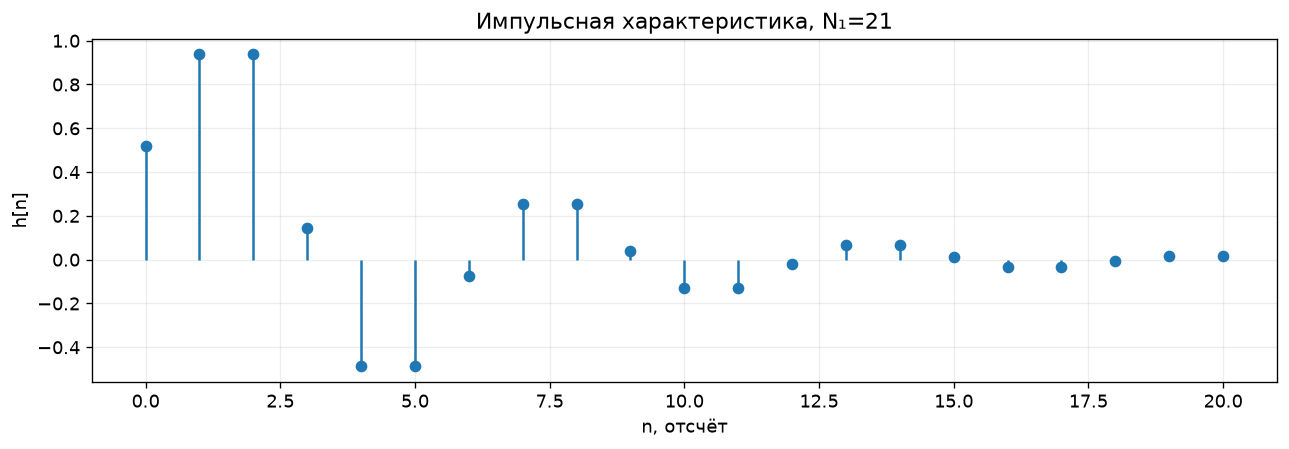

Отличие аналитической формулы от расчёта: 2.5e-16


In [4]:
r = np.sqrt(a[2])
theta = np.arccos(-a[1] / (2 * r))


def s(n):
    if n < 0:
        return 0.0
    return r**n * np.sin((n + 1) * theta) / np.sin(theta)


def h_analytic(indices):
    values = np.zeros(len(indices))
    for i in range(len(indices)):
        n = indices[i]
        values[i] = b0 * (s(n) + s(n - 1) + s(n - 2))
    return values


delta = np.zeros(N1)
delta[0] = 1
h = signal.lfilter(b, a, delta)
nh = np.arange(N1)
fig, ax = plt.subplots()
stems(ax, nh, h, "Импульсная характеристика, N₁=21", "n, отсчёт", "h[n]")
finish(fig, "01_impulse")
print(
    "Отличие аналитической формулы от расчёта: "
    f"{max(abs(h - h_analytic(nh))):.1e}"
)

Аналитическая формула совпадает с вычисленной импульсной характеристикой с точностью вычислений.
Импульсная характеристика бесконечна и затухает, поскольку $r<1$. Число $N_1=21$ задаёт длину рассчитанного фрагмента.

### Часть 1.2. Реакция по формуле свёртки

$$x[n]=\begin{cases}1,&0\leq n\leq15,\\0,&16\leq n\leq30.\end{cases}$$

Массив входа имеет длину 31, длительность ненулевого импульса — 16 отсчётов (16 мс при 1000 Гц).
Для массивов длины $N_2=31$ и $N_1=21$ полная свёртка содержит $N_1+N_2-1=51$ отсчёт, индексы 0–50.
Из-за 15 нулей в конце входа ненулевая часть свёртки содержит $16+21-1=36$ отсчётов.
По графику ненулевые значения занимают индексы 0–35; с $n=36$ до $n=50$ значения равны нулю.
Для сравнения реакций берутся первые 31 отсчёт — столько же, сколько во входном массиве. Реакция самой системы после 31-го отсчёта продолжается и затухает.

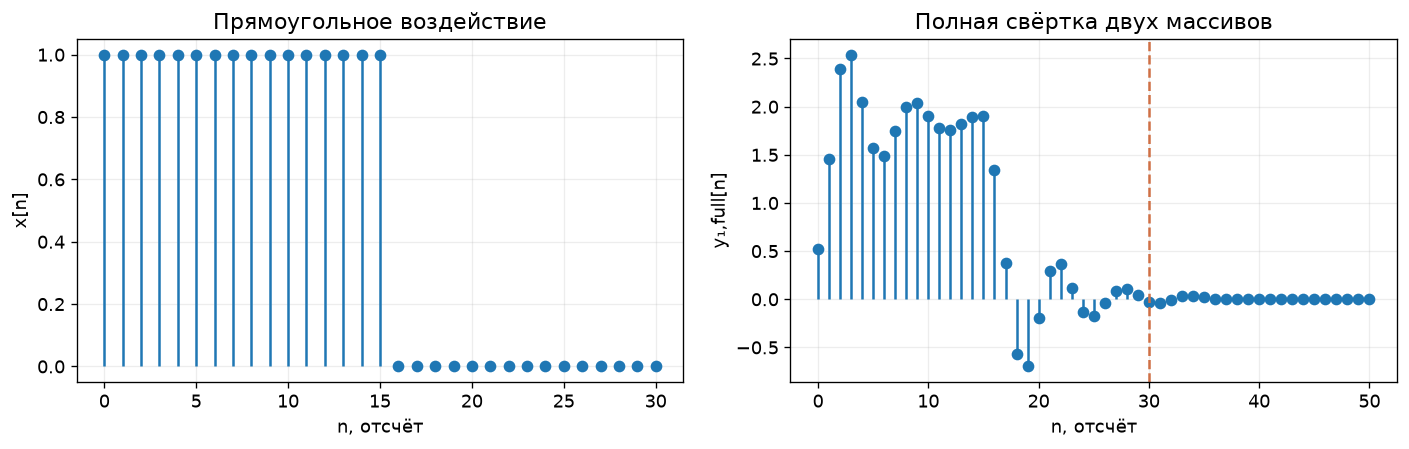

In [5]:
n_sys = np.arange(N2)
x_sys = np.zeros(N2)
x_sys[:L] = 1
y_conv_full = np.convolve(x_sys, h, mode="full")
y1 = y_conv_full[:N2]


fig, ax = plt.subplots(1, 2, figsize=(12, 4))
stems(ax[0], n_sys, x_sys, "Прямоугольное воздействие", "n, отсчёт", "x[n]")
stems(
    ax[1],
    np.arange(len(y_conv_full)),
    y_conv_full,
    "Полная свёртка двух массивов",
    "n, отсчёт",
    "y₁,full[n]",
)
ax[1].axvline(N2 - 1, color="#cf7045", ls="--")
finish(fig, "02_convolution")

### Часть 1.3. Разностное уравнение и сравнение реакций

Для данного варианта:

$$\boxed{y[n]=0.52x[n]+0.52x[n-1]+0.52x[n-2]+0.8028y[n-1]-0.646y[n-2].}$$

При $n<0$ вход и выход равны нулю. Для сравнения вычисляются свёртки с 21 и 31 отсчётом $h$.
В первом случае с $n=21$ появляется ошибка усечения; во втором первые 31 значение совпадают с решением разностного уравнения.

In [6]:
def difference_equation(x, b, a):
    y = np.zeros(len(x), dtype=float)
    for n in range(len(x)):
        y[n] = b[0] * x[n]
        if n >= 1:
            y[n] += b[1] * x[n - 1] - a[1] * y[n - 1]
        if n >= 2:
            y[n] += b[2] * x[n - 2] - a[2] * y[n - 2]
        y[n] = y[n] / a[0]
    return y


y2 = difference_equation(x_sys, b, a)
h31 = h_analytic(np.arange(N2))
y_exact_conv = np.convolve(x_sys, h31)[:N2]

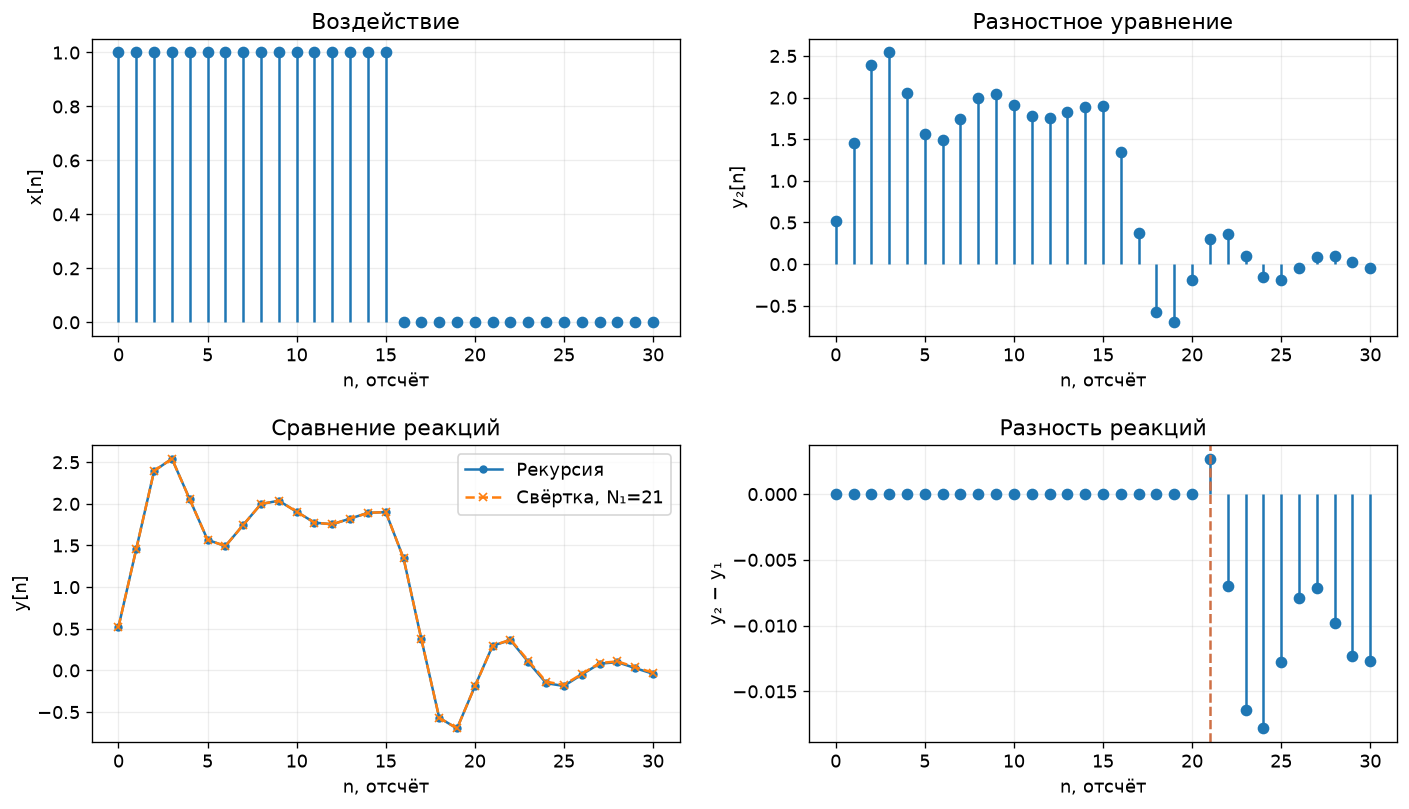

| Проверка | Максимальная абсолютная ошибка |
|---|---|
| Свёртка с 31 отсчётом h / рекурсия | 4.441e-16 |
| Свёртка с 21 отсчётом h / рекурсия | 1.783e-02 |


In [7]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
stems(ax[0, 0], n_sys, x_sys, "Воздействие", "n, отсчёт", "x[n]")
stems(ax[0, 1], n_sys, y2, "Разностное уравнение", "n, отсчёт", "y₂[n]")
ax[1, 0].plot(n_sys, y2, "o-", ms=4, label="Рекурсия")
ax[1, 0].plot(n_sys, y1, "x--", ms=5, label="Свёртка, N₁=21")
ax[1, 0].set(title="Сравнение реакций", xlabel="n, отсчёт", ylabel="y[n]")
ax[1, 0].legend()
stems(ax[1, 1], n_sys, y2 - y1, "Разность реакций", "n, отсчёт", "y₂ − y₁")
ax[1, 1].axvline(21, color="#cf7045", ls="--")
finish(fig, "03_recurrence")
table(
    ["Проверка", "Максимальная абсолютная ошибка"],
    [
        (
            "Свёртка с 31 отсчётом h / рекурсия",
            f"{max(abs(y2-y_exact_conv)):.3e}",
        ),
        (
            "Свёртка с 21 отсчётом h / рекурсия",
            f"{max(abs(y2-y1)):.3e}",
        ),
    ],
)

Графики $y_1$ и $y_2$ визуально почти совпадают. Различие появляется с $n=21$ из-за усечения $h$ до 21 отсчёта и не превышает 0.018; максимум достигается при $n=24$.
Входной массив и вычисленная реакция содержат по 31 отсчёту. При нулевом продолжении входа реакция продолжается бесконечно и затухает.

### Часть 1.4. Нули, полюсы и факторизация

После умножения числителя и знаменателя на $z^2$:

$$H(z)=0.52\frac{z^2+z+1}{z^2-0.8028z+0.646}.$$

Нули $z_{1,2}=-\frac12\pm j\frac{\sqrt3}{2}=e^{\pm j2\pi/3}$.
Полюсы $p_{1,2}=0.4014\pm j\sqrt{0.646-0.4014^2}=re^{\pm j\theta}$.
Переход от алгебраической формы $u+jv$ к показательной:
$\rho=\sqrt{u^2+v^2}$, $\alpha=\operatorname{atan2}(v,u)$, $u+jv=\rho e^{j\alpha}$.
Сопряжённость пар следует из вещественных коэффициентов полиномов.

$$\boxed{H(z)=0.52\frac{(z-e^{j2\pi/3})(z-e^{-j2\pi/3})}{(z-re^{j\theta})(z-re^{-j\theta})},\quad r=\sqrt{0.646},\quad\theta=\arccos\frac{0.8028}{2\sqrt{0.646}}.}$$

In [8]:
zeros = np.roots(b)
poles = np.roots(a)
rows = []
for kind, values in [("Нуль", zeros), ("Полюс", poles)]:
    for value in values:
        radius = abs(value)
        angle_pi = np.angle(value) / np.pi
        algebraic = f"{value.real:.6f} {value.imag:+.6f}j"
        exponential = f"{radius:.6f} exp(jπ·{angle_pi:+.6f})"
        rows.append([kind, algebraic, f"{radius:.6f}", f"{angle_pi:+.6f}", exponential])
table(
    ["Тип", "Алгебраическая форма", "Модуль", "Угол / π", "Показательная форма"], rows
)

| Тип | Алгебраическая форма | Модуль | Угол / π | Показательная форма |
|---|---|---|---|---|
| Нуль | -0.500000 +0.866025j | 1.000000 | +0.666667 | 1.000000 exp(jπ·+0.666667) |
| Нуль | -0.500000 -0.866025j | 1.000000 | -0.666667 | 1.000000 exp(jπ·-0.666667) |
| Полюс | 0.401400 +0.696332j | 0.803741 | +0.333549 | 0.803741 exp(jπ·+0.333549) |
| Полюс | 0.401400 -0.696332j | 0.803741 | -0.333549 | 0.803741 exp(jπ·-0.333549) |


### Часть 1.5. Карта нулей и полюсов. Устойчивость

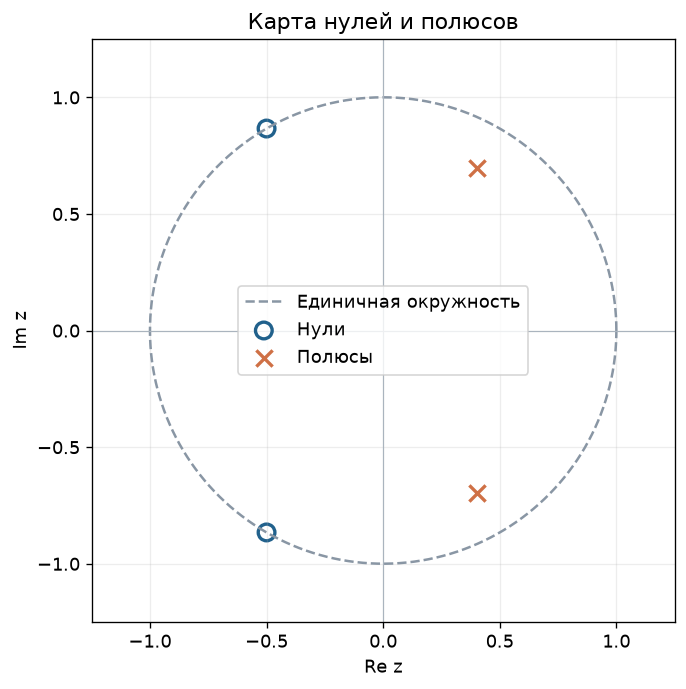

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 6))
tt = np.linspace(0, 2 * np.pi, 600)
ax.plot(np.cos(tt), np.sin(tt), color="#8996a4", ls="--", label="Единичная окружность")
ax.scatter(
    zeros.real,
    zeros.imag,
    s=100,
    facecolors="none",
    edgecolors="#21618c",
    lw=2,
    label="Нули",
)
ax.scatter(
    poles.real,
    poles.imag,
    s=95,
    marker="x",
    color="#cf7045",
    lw=2,
    label="Полюсы",
)
ax.axhline(0, color="#aab4be", lw=0.7)
ax.axvline(0, color="#aab4be", lw=0.7)
ax.set(
    xlim=(-1.25, 1.25),
    ylim=(-1.25, 1.25),
    xlabel="Re z",
    ylabel="Im z",
    title="Карта нулей и полюсов",
)
ax.set_aspect("equal")
ax.legend(loc="center")
finish(fig, "05_poles_zeros")

Звено устойчиво: модули обоих полюсов $|p_{1,2}|\approx0.803741<1$.
Нули на единичной окружности не нарушают устойчивость: её определяют полюсы.
Координаты на карте совпадают с вычисленными корнями.
Область сходимости причинной системы $|z|>r$ содержит единичную окружность.

### Часть 1.6. АЧХ и ФЧХ в нормированной шкале

Нули на углах $\pm2\pi/3$ создают точные провалы АЧХ при $\hat\omega=\pm2\pi/3$.
Максимум АЧХ находится при $\hat\omega\approx0.316\pi$, угол положительного полюса — $0.334\pi$. Положение максимума определяется числителем и знаменателем передаточной функции.
Положительная основная полоса: $0\leq\hat\omega\leq\pi$ рад/отсчёт.

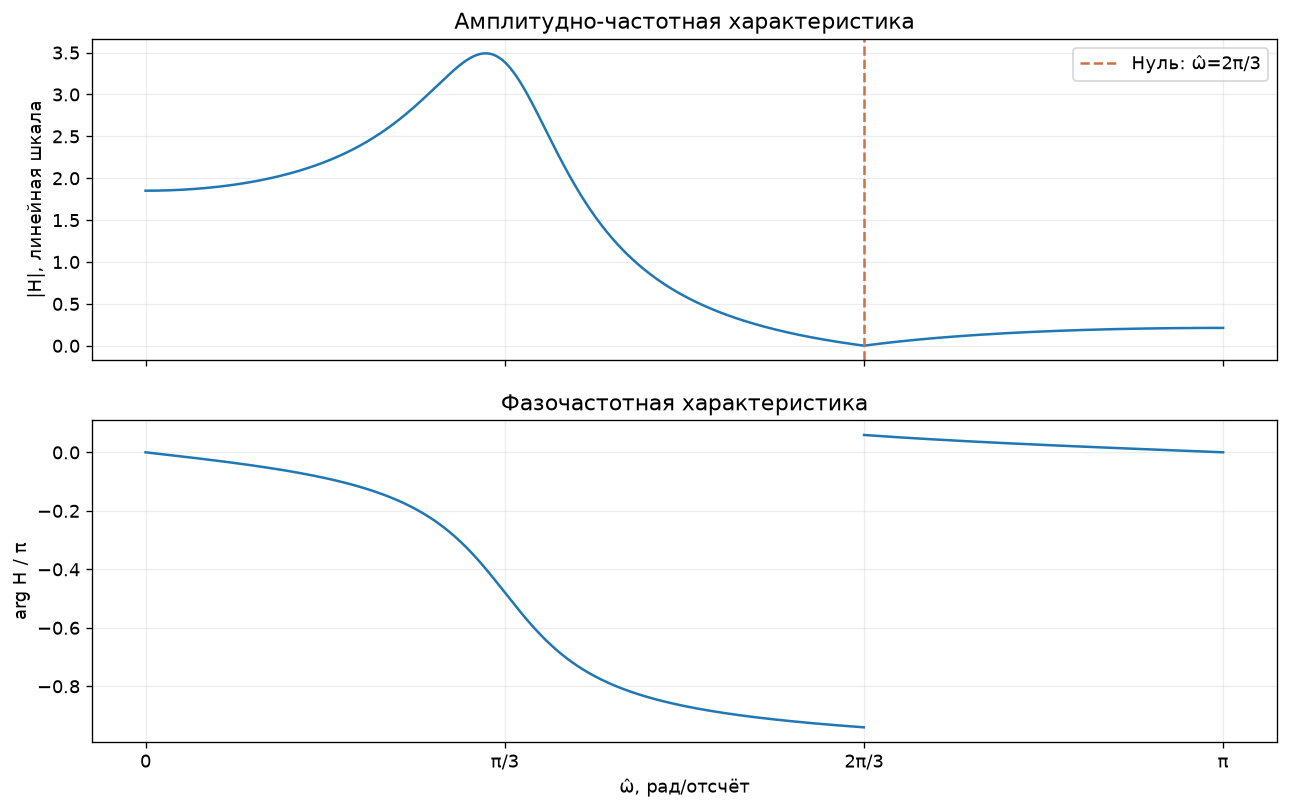

| Частота ω̂ | \|H\| | Фаза / π |
|---|---|---|
| 0 | 1.850094877 | 0.000000000 |
| 2π/3 | 0.000000000 | не определена |
| π | 0.212348906 | 0.000000000 |


In [10]:
w = np.linspace(0, np.pi, 8194)
w, H = signal.freqz(b, a, worN=w)
amp = abs(H)
phase = np.angle(H)
phase[amp < 1e-10] = np.nan
_, special = signal.freqz(b, a, worN=np.array([0.0, 2 * np.pi / 3, np.pi]))
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(w, amp)
ax[0].axvline(2 * np.pi / 3, color="#cf7045", ls="--", label="Нуль: ω̂=2π/3")
ax[0].set(title="Амплитудно-частотная характеристика", ylabel="|H|, линейная шкала")
ax[0].legend()
ax[1].plot(w, phase / np.pi)
ax[1].set(
    title="Фазочастотная характеристика",
    xlabel="ω̂, рад/отсчёт",
    ylabel="arg H / π",
)
ax[1].set_xticks([0, np.pi / 3, 2 * np.pi / 3, np.pi])
ax[1].set_xticklabels(["0", "π/3", "2π/3", "π"])
finish(fig, "06_frequency_normalized")
rows = []
frequency_names = ["0", "2π/3", "π"]
for i in range(3):
    value = special[i]
    if abs(value) < 1e-10:
        phase_text = "не определена"
    else:
        phase_text = f"{np.angle(value)/np.pi:.9f}"
    rows.append([frequency_names[i], f"{abs(value):.9f}", phase_text])
table(["Частота ω̂", "|H|", "Фаза / π"], rows)

Односторонние пределы фазы при $\hat\omega=2\pi/3$ различаются на $\pi$.
В этой точке АЧХ равна нулю, а фаза не определена.
При постоянном входе коэффициент передачи $H(1)=1.56/0.8432\approx1.850095$, а при частоте Найквиста $H(-1)=0.52/2.4488\approx0.212349$.
АЧХ немонотонна: максимум около 3.49 при 157.8 Гц. Уровень $|H|=1$ достигается при $\hat\omega\approx0.455\pi$ (227.3 Гц); выше этой границы коэффициент передачи меньше 1.
Высокочастотные составляющие фронтов прямоугольного импульса ослаблены, поэтому переходы в реакции растянуты во времени. Составляющие около $\hat\omega=\pi/3$ усилены: на участке импульса реакция колеблется около $H(1)\approx1.85$, достигая 2.54 при $n=3$.
После окончания импульса реакция затухает колебаниями с периодом около 6 отсчётов: $2\pi/\theta\approx6.0$.

### Часть 1.7. АЧХ и ФЧХ в герцах

При $f_s=1000$ Гц связь шкал: $f=\hat\omega f_s/(2\pi)$.
Соответствия: $\hat\omega=\pi/3$ — 166.7 Гц, $2\pi/3$ — 333.3 Гц, $\pi$ — 500 Гц; максимум при $\hat\omega\approx0.316\pi$ — 157.8 Гц.
Основная двусторонняя полоса — $[-500;500)$ Гц, положительная половина — $[0;500]$ Гц.
Провал расположен при $f=f_s/3=333.\overline3$ Гц.

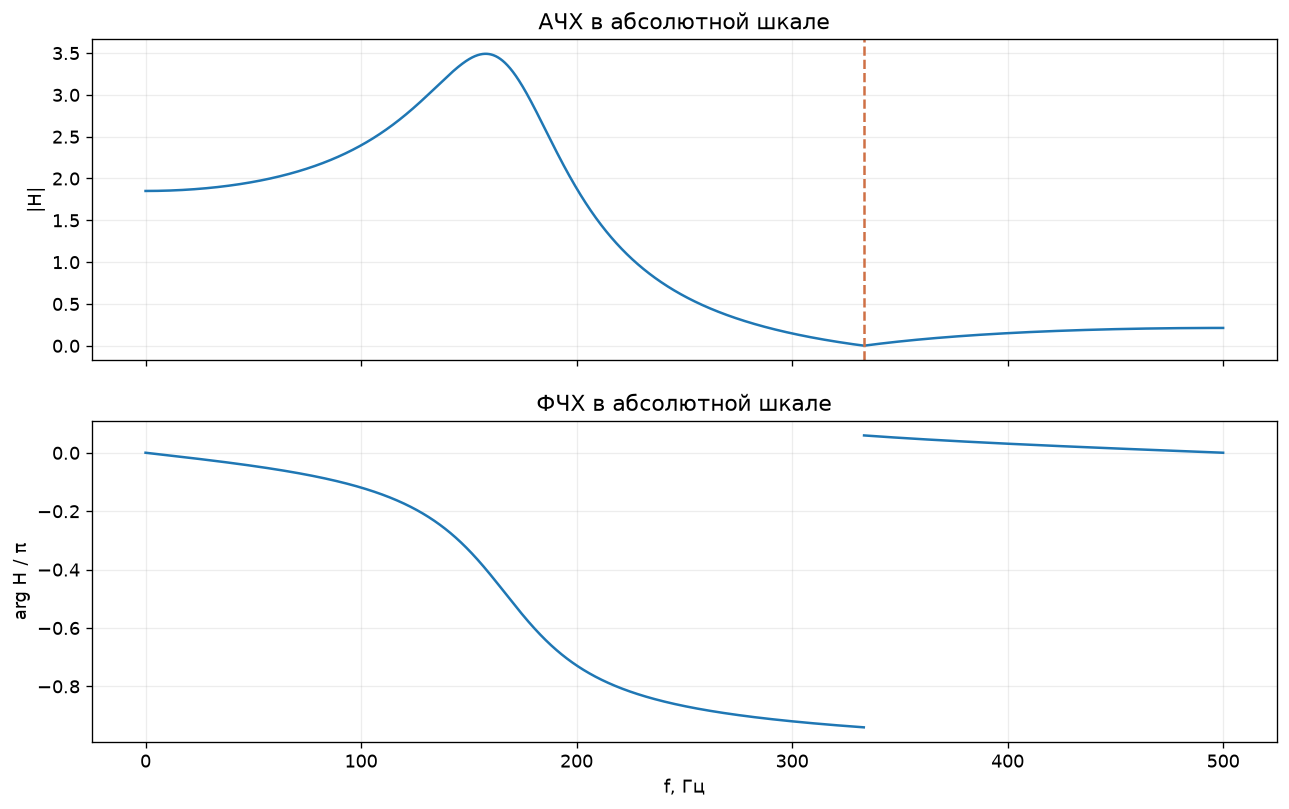

In [11]:
f_hz, H_hz = signal.freqz(b, a, worN=w * fs_sys / (2 * np.pi), fs=fs_sys)

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(f_hz, abs(H_hz))
ax[0].axvline(fs_sys / 3, color="#cf7045", ls="--")
ax[0].set(title="АЧХ в абсолютной шкале", ylabel="|H|")
ax[1].plot(f_hz, phase / np.pi)
ax[1].set(title="ФЧХ в абсолютной шкале", xlabel="f, Гц", ylabel="arg H / π")
finish(fig, "07_frequency_hz")

### Часть 2.1. Периодическая последовательность

$$x[n]=1.01\cos(2\pi\,500\,nT+\pi/4)+2.02\cos(2\pi\,750\,nT+\pi/8),\qquad T=1/4000.$$

Дискретное время $t_n=nT$ имеет шаг $T=0.25$ мс.
Дискретное нормированное время $n=t_n/T$ — номер отсчёта с шагом 1.
Минимальный период суммы — 16 отсчётов: за это время первая гармоника совершает 2 колебания, вторая — 3.
Заданный период $N=64$ содержит 4 таких периода.

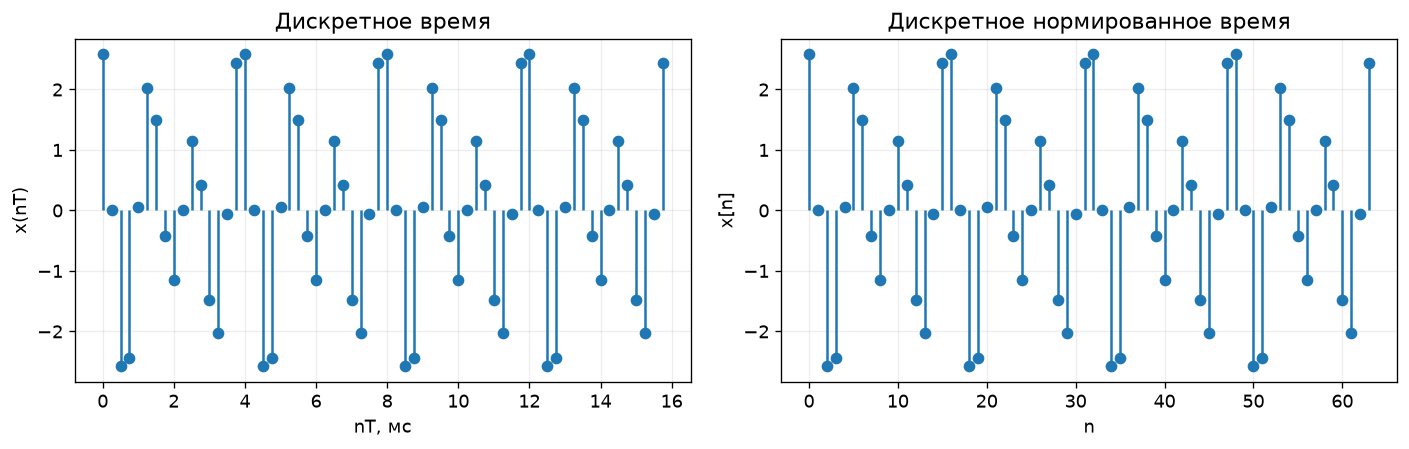

In [12]:
n = np.arange(N)
t = n * T
harmonic1 = A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4)
harmonic2 = A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8)
x = harmonic1 + harmonic2
X = np.fft.fft(x)
C = X / N
nu = np.fft.fftfreq(N)
freq = np.fft.fftfreq(N, T)
Xc = np.fft.fftshift(X)
nu_c, f_c = np.fft.fftshift(nu), np.fft.fftshift(freq)
mask = abs(Xc) > 1e-10
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
stems(ax[0], t * 1000, x, "Дискретное время", "nT, мс", "x(nT)")
stems(ax[1], n, x, "Дискретное нормированное время", "n", "x[n]")
finish(fig, "08_sequence")

### Часть 2.2. Обратное ДПФ

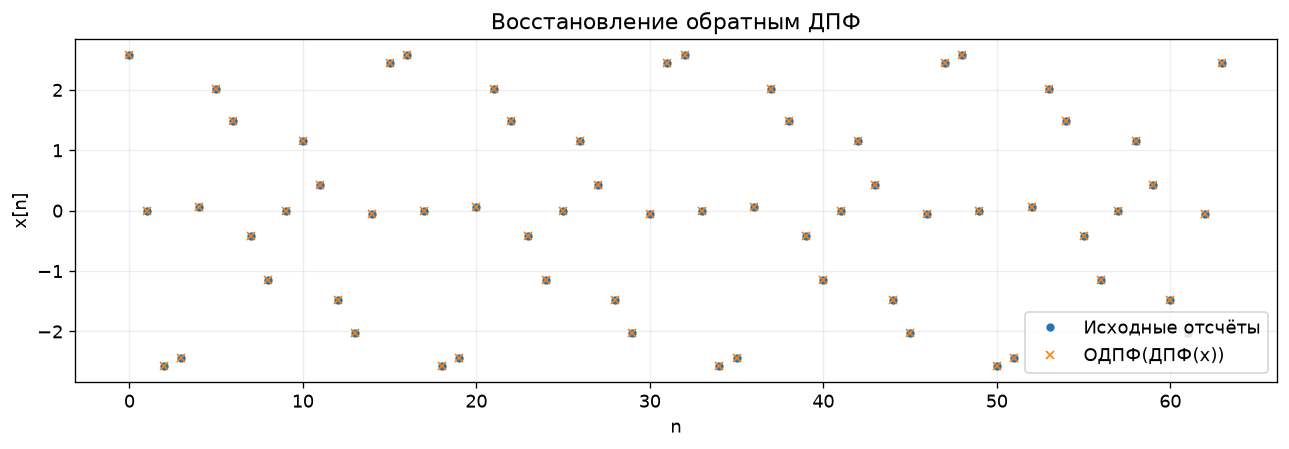

Максимальная ошибка ОДПФ: 5.130e-16


In [13]:
x_idft = np.fft.ifft(X)
fig, ax = plt.subplots()
ax.plot(n, x, "o", ms=4, label="Исходные отсчёты")
ax.plot(n, x_idft.real, "x", ms=5, label="ОДПФ(ДПФ(x))")
ax.set(title="Восстановление обратным ДПФ", xlabel="n", ylabel="x[n]")
ax.legend()
finish(fig, "09_idft")
print(f"Максимальная ошибка ОДПФ: {max(abs(x_idft-x)):.3e}")

ОДПФ восстанавливает исходные 64 отсчёта с погрешностью арифметики с плавающей точкой.

### Часть 2.3. Амплитудный и фазовый спектры в двух шкалах

Частоты отсчётов ДПФ:

$$f_k=\frac{f_s}{N}\begin{cases}k,&0\leq k<N/2,\\k-N,&N/2\leq k<N,\end{cases}\qquad\nu_k=\frac{f_k}{f_s}.$$

При $N=64$ индексы 32–63 соответствуют отрицательным частотам: вместо $k$ используется $k-64$.
Шаг сетки $\Delta f=f_s/N=62.5$ Гц, $\Delta\nu=1/64$.
Основная полоса $-0.5\leq\nu<0.5$ соответствует $-2000\leq f<2000$ Гц.
Показан двусторонний спектр в нормировке ДПФ: модули линий при $\pm500$ Гц равны 32.32, при $\pm750$ Гц — 64.64.
На положительных частотах фазы равны $\pi/4$ и $\pi/8$, на отрицательных — противоположны им.

Четыре ненулевые линии ДПФ:
$X[8]=32.32e^{j\pi/4}$, $X[56]=32.32e^{-j\pi/4}$ при $\pm500$ Гц;
$X[12]=64.64e^{j\pi/8}$, $X[52]=64.64e^{-j\pi/8}$ при $\pm750$ Гц.

| k | f, Гц | ν = f/fs | \|X[k]\| | \|C[k]\| | Фаза / π |
|---|---|---|---|---|---|
| 8 | 500.0 | 0.1250 | 32.320000 | 0.505000 | +0.250000 |
| 12 | 750.0 | 0.1875 | 64.640000 | 1.010000 | +0.125000 |
| 52 | -750.0 | -0.1875 | 64.640000 | 1.010000 | -0.125000 |
| 56 | -500.0 | -0.1250 | 32.320000 | 0.505000 | -0.250000 |


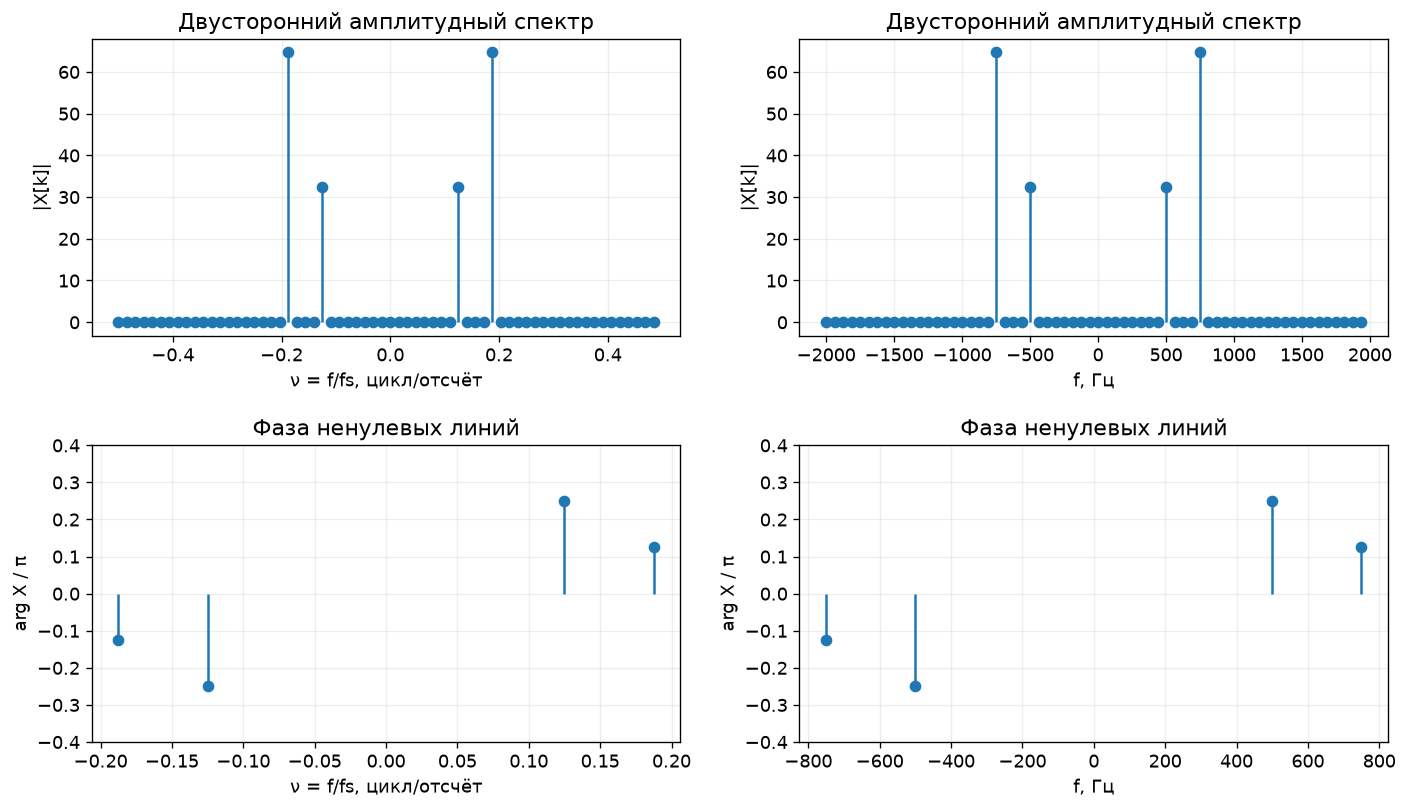

In [14]:
rows = []
for i in range(N):
    if abs(C[i]) > 1e-10:
        rows.append(
            [
                i,
                f"{freq[i]:.1f}",
                f"{nu[i]:.4f}",
                f"{abs(X[i]):.6f}",
                f"{abs(C[i]):.6f}",
                f"{np.angle(C[i])/np.pi:+.6f}",
            ]
        )
table(["k", "f, Гц", "ν = f/fs", "|X[k]|", "|C[k]|", "Фаза / π"], rows)

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
stems(
    ax[0, 0],
    nu_c,
    abs(Xc),
    "Двусторонний амплитудный спектр",
    "ν = f/fs, цикл/отсчёт",
    "|X[k]|",
)
stems(ax[0, 1], f_c, abs(Xc), "Двусторонний амплитудный спектр", "f, Гц", "|X[k]|")
stems(
    ax[1, 0],
    nu_c[mask],
    np.angle(Xc[mask]) / np.pi,
    "Фаза ненулевых линий",
    "ν = f/fs, цикл/отсчёт",
    "arg X / π",
)
stems(
    ax[1, 1],
    f_c[mask],
    np.angle(Xc[mask]) / np.pi,
    "Фаза ненулевых линий",
    "f, Гц",
    "arg X / π",
)
for aa in [ax[1, 0], ax[1, 1]]:
    aa.set_ylim(-0.4, 0.4)
finish(fig, "10_spectra")

Модуль спектра чётный, фазы сопряжённых линий имеют противоположные знаки — следствие вещественности сигнала.
Фаза не рисуется для почти нулевых коэффициентов: их случайные численные аргументы не характеризуют сигнал.

### Часть 2.4. ДПФ конечного блока и спектр периодической последовательности

ДПФ одного периода и ДПФ конечного блока из тех же $N$ отсчётов совпадают: $X_p[k]=X_{fin}[k]$.
У периодической последовательности спектр линейчатый. У конечного блока преобразование Фурье определено для непрерывной частоты, а ДПФ содержит его значения на сетке $k/N$.
Коэффициенты ряда $C[k]=X_p[k]/N$ — отдельная нормированная величина, используемая при восстановлении аналогового сигнала.

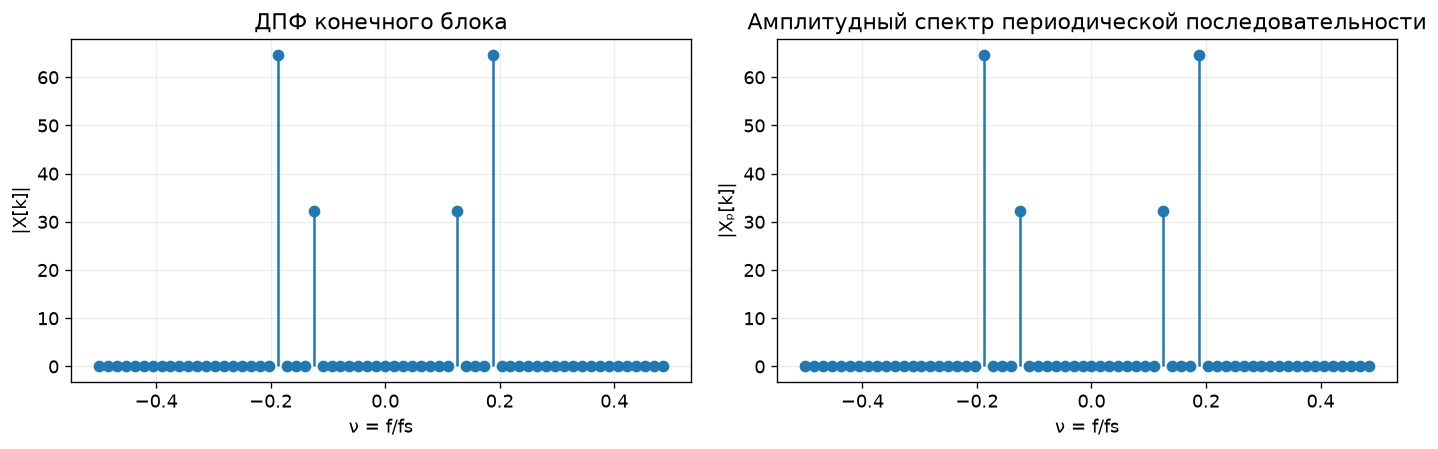

In [15]:
X_finite = np.fft.fft(x)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
stems(
    ax[0], nu_c, abs(np.fft.fftshift(X_finite)),
    "ДПФ конечного блока", "ν = f/fs", "|X[k]|",
)
stems(
    ax[1],
    nu_c,
    abs(Xc),
    "Амплитудный спектр периодической последовательности",
    "ν = f/fs",
    "|Xₚ[k]|",
)
finish(fig, "11_dft_scaling")

### Часть 2.5. Восстановление аналогового сигнала

В сумме восстановления $k=-32,\ldots,31$ и $X_a[k]=X[k\bmod64]$.
Сетка времени содержит 253 точки, включая оба конца: $t\in[0;63T]$, $\Delta t=T/4=0.0000625$ с.
Сравнение проводится с исходной непрерывной суммой косинусов на всей сетке восстановления.

In [16]:
k_signed = np.arange(-N // 2, N // 2)
Xa = np.zeros(N, dtype=complex)
for i in range(N):
    k_value = k_signed[i]
    if k_value < 0:
        Xa[i] = X[N + k_value]
    else:
        Xa[i] = X[k_value]

t_fine = np.arange(4 * (N - 1) + 1) * (T / 4)


def restore_signal(coefficients, times):
    restored = np.zeros(len(times), dtype=complex)
    for i in range(len(times)):
        for j in range(N):
            k_value = j - N // 2
            angle = 2 * np.pi * k_value * times[i] / (N * T)
            restored[i] += coefficients[j] * np.exp(1j * angle)
        restored[i] = restored[i] / N
    return restored


x_rec = restore_signal(Xa, t_fine)
x_analog = A1 * np.cos(2 * np.pi * f1 * t_fine + np.pi / 4) + A2 * np.cos(
    2 * np.pi * f2 * t_fine + np.pi / 8
)

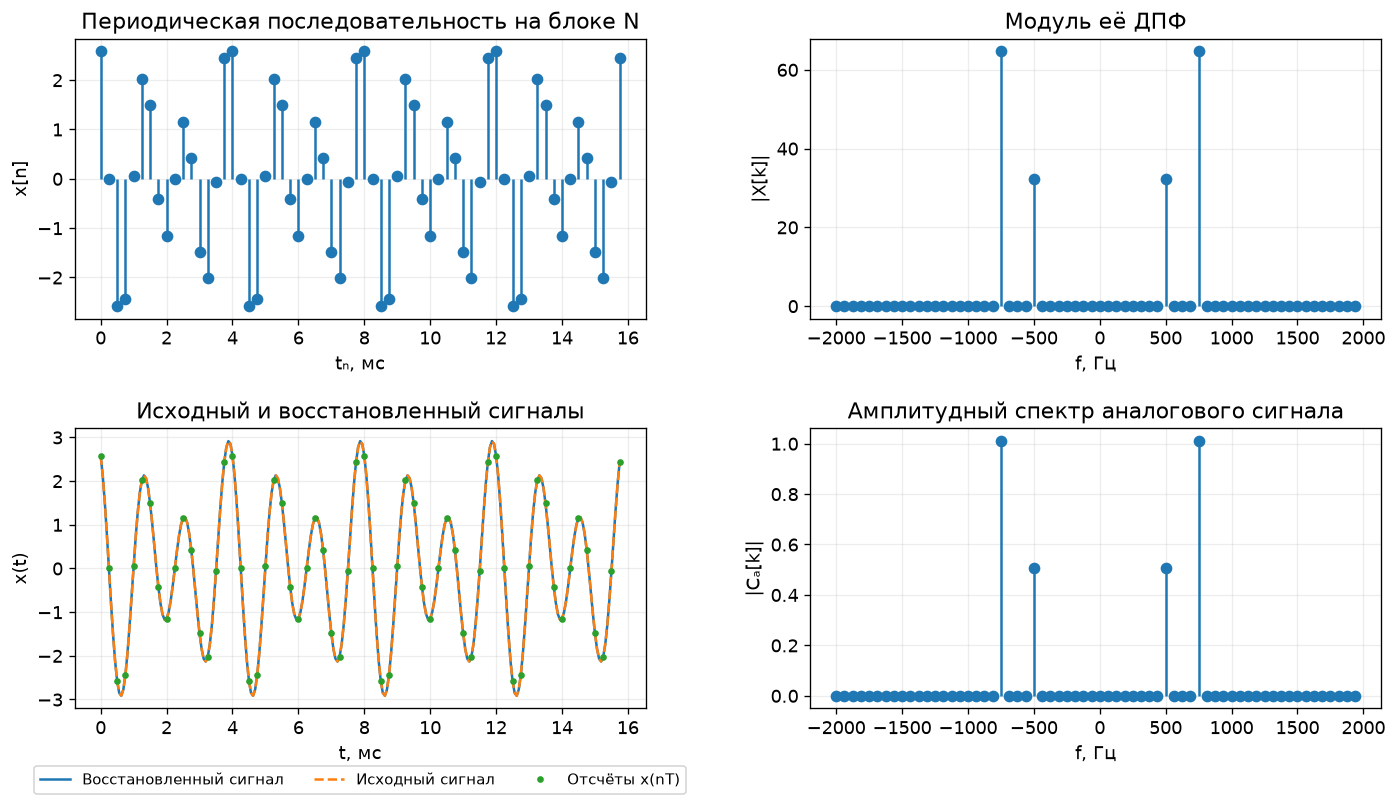

Ошибка восстановления: 4.158e-14


In [17]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
stems(
    ax[0, 0],
    t * 1000,
    x,
    "Периодическая последовательность на блоке N",
    "tₙ, мс",
    "x[n]",
)
stems(ax[0, 1], f_c, abs(Xc), "Модуль её ДПФ", "f, Гц", "|X[k]|")
ax[1, 0].plot(t_fine * 1000, x_rec.real, label="Восстановленный сигнал")
ax[1, 0].plot(t_fine * 1000, x_analog, "--", label="Исходный сигнал")
ax[1, 0].plot(t * 1000, x, "o", ms=3, label="Отсчёты x(nT)")
ax[1, 0].set(title="Исходный и восстановленный сигналы", xlabel="t, мс", ylabel="x(t)")
ax[1, 0].legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=9
)
stems(
    ax[1, 1],
    f_c,
    abs(Xa) / N,
    "Амплитудный спектр аналогового сигнала",
    "f, Гц",
    "|Cₐ[k]|",
)
finish(fig, "12_analog_reconstruction")
print(f"Ошибка восстановления: {max(abs(x_rec-x_analog)):.3e}")

### Часть 2.6. Связь спектров и интерпретация восстановления

Аналоговый сигнал восстанавливается сложением гармоник с частотами $k/(NT)$ и коэффициентами $C_a[k]=X_a[k]/N$.
Поэтому высота каждой линии на графике равна $|X_a[k]|/N$.
Для косинуса учитываются две линии на частотах $+f_0$ и $-f_0$. Его амплитуда равна $2|X[k]|/N$.
В непрерывном преобразовании Фурье линии записываются как $\sum_k C_a[k]\delta(f-k/(NT))$:
стержни на графике показывают модули коэффициентов при дельта-функциях.

Обе частоты, 500 и 750 Гц, ниже половины частоты дискретизации (2000 Гц) и входят в частотную сетку ДПФ.
Поэтому исходная сумма косинусов восстанавливается и в отсчётах, и между ними.
На графике восстановленный и исходный сигналы визуально совпадают: кривые неразличимы. Наибольшее расхождение порядка $10^{-14}$ связано с ограниченной точностью вычислений.

### Часть 2.7. Равенство Парсеваля

За $N=64$ отсчёта обе гармоники совершают целое число колебаний: 8 и 12.
Сумма их произведений на этом интервале равна нулю, поэтому мощности складываются:

$$P=\frac{A_1^2+A_2^2}{2}=2.55025,\qquad E_N=NP=163.216.$$

In [18]:
E_time = float(np.sum(abs(x) ** 2))
E_freq = float(np.sum(abs(X) ** 2) / N)
P_time = E_time / N
P_freq = float(np.sum(abs(C) ** 2))


table(
    ["Величина", "Временная область", "Частотная область", "Абсолютная разность"],
    [
        (
            "Энергия блока",
            f"{E_time:.12f}",
            f"{E_freq:.12f}",
            f"{abs(E_time-E_freq):.3e}",
        ),
        (
            "Средняя мощность",
            f"{P_time:.12f}",
            f"{P_freq:.12f}",
            f"{abs(P_time-P_freq):.3e}",
        ),
    ],
)

| Величина | Временная область | Частотная область | Абсолютная разность |
|---|---|---|---|
| Энергия блока | 163.216000000000 | 163.216000000000 | 2.842e-14 |
| Средняя мощность | 2.550250000000 | 2.550250000000 | 4.441e-16 |


Смысл равенства Парсеваля: энергия блока одинакова при вычислении по отсчётам и по спектру. ДПФ представляет её как сумму вкладов спектральных линий; множитель $1/N$ учитывает отсутствие нормировки в прямом ДПФ.
Линии $\pm500$ Гц дают вклад $2\cdot32.32^2/64=32.6432$, линии $\pm750$ Гц — $2\cdot64.64^2/64=130.5728$; сумма равна 163.216.
Это дискретная энергия блока в квадрате единиц амплитуды.

## Выводы

1. Импульсная характеристика системы бесконечна и затухает. Рассчитаны первые 21 отсчёт.
2. Входной массив содержит 31 отсчёт, из них 16 единичных. Полная свёртка содержит 51 значение, из них 36 ненулевых. Для сравнения реакций используются первые 31 значение.
3. Свёртка и разностное уравнение дают одинаковый результат при достаточной длине $h$. Усечение до 21 отсчёта создаёт ошибку начиная с $n=21$.
4. Модуль полюсов равен 0.803741 и меньше 1, поэтому система устойчива. АЧХ имеет провал на 333.333… Гц; в этой точке фаза не определена. Высокие частоты в целом подавляются сильнее низких.
5. Последовательность содержит гармоники 500 и 750 Гц. Модули соответствующих линий ДПФ равны 32.32 и 64.64; модули спектральных коэффициентов аналогового сигнала — 0.505 и 1.01. Минимальный период — 16 отсчётов; $N=64$ содержит четыре минимальных периода.
6. ОДПФ и восстановление на сетке $T/4$ совпали с исходным сигналом с погрешностью менее $10^{-12}$. Равенство Парсеваля выполнено: энергия блока 163.216, средняя мощность 2.55025.